# BAL cell segmentation + classification

Pipeline: segment every cell in `bal2.zarr` (series 2, `40x_BF_01`, the complete high-res scan) with **Cellpose-SAM**, then group cells into a handful of morphology/color-based classes.

Runs in the `cellpose_seg` conda env (separate from the data-prep notebook) because it needs CUDA PyTorch — this machine has an RTX A2000, and Cellpose-SAM is far too slow to run whole-slide on CPU. Confirmed working: model loads on `cuda:0`, ~2s/tile at 1024x1024.

**Stages:**
1. **Tissue tiling** — reuse the background filter from the data-prep notebook to skip empty tiles (most of the 52623x55481 slide is blank slide, not smear).
2. **Tiled segmentation** — run Cellpose-SAM per tile with an overlap margin, keep only instances centered in each tile's core region (standard tiled-inference stitching, avoids double-counting cells cut at tile edges).
3. **Feature extraction** — per cell: size/shape (regionprops) + color + a nucleus-fraction proxy (N:C ratio) from thresholding within the mask, since that's a primary way cytologists tell these cell types apart by eye.
4. **Grouping** — no labels exist for this slide yet, so start unsupervised: standardize features, k-means into k=3-5 clusters, then inspect example crops per cluster to assign real names (macrophage / lymphocyte / neutrophil / eosinophil / other — the standard BAL differential categories). Documented at the end: how to turn this into a supervised classifier once you've curated labels.

Output: a per-cell table (global centroid, size, color/shape features, cluster id) — not a full-resolution label image (52623x55481 would be tens of GB), though the code below shows how to keep per-tile masks if you want them for QC.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import zarr
import torch
import matplotlib.pyplot as plt
from cellpose import models
from skimage import measure, filters, color as skcolor

assert torch.cuda.is_available(), "expected CUDA in the cellpose_seg env"

zarr_root = Path("../SFS/bal2.zarr")
full_res = zarr.open(zarr_root / "2" / "0", mode="r")
PIXEL_SIZE_UM = 0.137  # from OME metadata (physical_size_x for 40x_BF_01)
print(f"full_res shape: {full_res.shape}")

model = models.CellposeModel(gpu=True)
print("model device:", model.device)

full_res shape: (1, 3, 1, 52623, 55481)
model device: cuda:0


In [2]:
def read_tile(z, y0, x0, size, y1=None, x1=None):
    y1 = min(y1 if y1 is not None else y0 + size, z.shape[3])
    x1 = min(x1 if x1 is not None else x0 + size, z.shape[4])
    y0, x0 = max(y0, 0), max(x0, 0)
    tile = z[0, :, 0, y0:y1, x0:x1]
    return np.moveaxis(tile, 0, -1)


def find_tissue_tiles(z, size=1024, bg_value=225, max_bg_frac=0.9):
    """Scan the full grid and return (y0, x0) origins of tiles that aren't mostly background."""
    height, width = z.shape[3], z.shape[4]
    origins = []
    for y0 in range(0, height, size):
        for x0 in range(0, width, size):
            tile = read_tile(z, y0, x0, size)
            bg_frac = (tile.mean(axis=-1) > bg_value).mean()
            if bg_frac <= max_bg_frac:
                origins.append((y0, x0))
    return origins

In [3]:
def segment_tile(model, z, y0, x0, size=1024, margin=64):
    """Segment one tile with a halo, keeping only cells centered in the tile's core.

    Reads (size + 2*margin) pixels so cells near the tile edge are seen whole by
    the model, then discards instances whose centroid falls in the halo -- they'll
    be (fully) picked up by the neighboring tile instead. Standard tiled-inference
    stitching; avoids double-counting or clipping cells at tile boundaries.

    Returns the padded RGB crop, the raw instance mask, and a list of dicts for
    the kept instances with centroids already in global slide coordinates.
    """
    y0p, x0p = y0 - margin, x0 - margin
    y1p, x1p = y0 + size + margin, x0 + size + margin
    tile = read_tile(z, y0p, x0p, None, y1=y1p, x1=x1p)
    read_y0 = max(y0p, 0)
    read_x0 = max(x0p, 0)

    masks, _, _ = model.eval(tile, diameter=None)

    core_y0, core_x0 = y0 - read_y0, x0 - read_x0
    core_y1, core_x1 = core_y0 + size, core_x0 + size

    kept = []
    for prop in measure.regionprops(masks):
        cy, cx = prop.centroid
        if core_y0 <= cy < core_y1 and core_x0 <= cx < core_x1:
            kept.append({
                "label": prop.label,
                "global_y": read_y0 + cy,
                "global_x": read_x0 + cx,
            })
    return tile, masks, kept

In [5]:
def _nucleus_fraction(rgb_crop, mask_crop):
    """Rough N:C proxy: fraction of the cell's masked pixels that are 'dark' (nucleus-like).

    Giemsa/Diff-Quik-stained nuclei are the darkest, most saturated-blue part of the
    cell; cytoplasm is lighter. Otsu-threshold luminance *within this cell's own
    pixels* (not globally) so it adapts to per-cell staining intensity.
    """
    gray = skcolor.rgb2gray(rgb_crop)
    values = gray[mask_crop]
    if values.min() == values.max():
        return 0.0
    thresh = filters.threshold_otsu(values)
    return float((values < thresh).mean())


def extract_features(tile, masks, kept, pixel_size_um=PIXEL_SIZE_UM):
    """Per kept cell: shape (regionprops) + color + nucleus-fraction features."""
    rows = []
    props = {p.label: p for p in measure.regionprops(masks)}
    for cell in kept:
        p = props[cell["label"]]
        y0, x0, y1, x1 = p.bbox
        mask_crop = masks[y0:y1, x0:x1] == cell["label"]
        rgb_crop = tile[y0:y1, x0:x1]
        pixels = rgb_crop[mask_crop]

        hsv = skcolor.rgb2hsv(rgb_crop)[mask_crop]

        rows.append({
            "global_y": cell["global_y"],
            "global_x": cell["global_x"],
            "area_um2": p.area * pixel_size_um ** 2,
            "equiv_diameter_um": p.equivalent_diameter_area * pixel_size_um,
            "eccentricity": p.eccentricity,
            "solidity": p.solidity,
            "extent": p.extent,
            "mean_r": pixels[:, 0].mean(), "mean_g": pixels[:, 1].mean(), "mean_b": pixels[:, 2].mean(),
            "std_intensity": skcolor.rgb2gray(rgb_crop)[mask_crop].std(),
            "mean_hue": hsv[:, 0].mean(), "mean_sat": hsv[:, 1].mean(),
            "nucleus_fraction": _nucleus_fraction(rgb_crop, mask_crop),
        })
    return rows

## Demo run

Same tissue region used in the data-prep notebook's `iter_tiles` demo (`y=0..5120`, `x=12288..18432`) — quick to run, known to contain real cells, good for validating the pipeline before committing to a full-slide run.

For the real run: swap `demo_tiles` for `find_tissue_tiles(full_res)` — see the runtime note at the end for a measured full-slide estimate (~43 min on this GPU).

12 tissue tiles in demo region


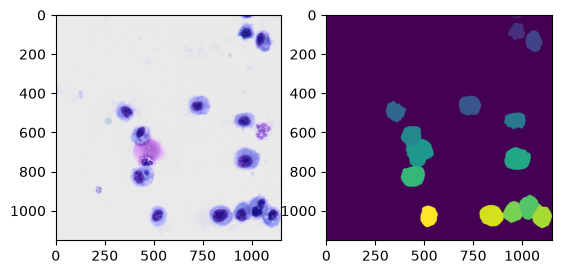

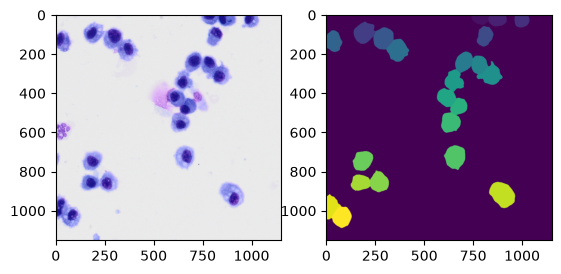

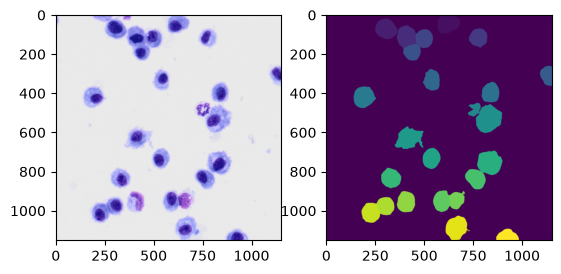

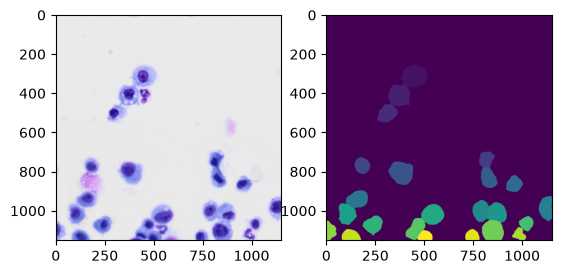

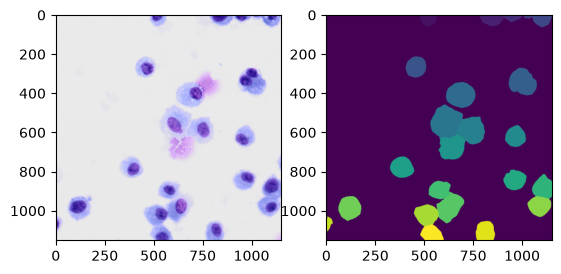

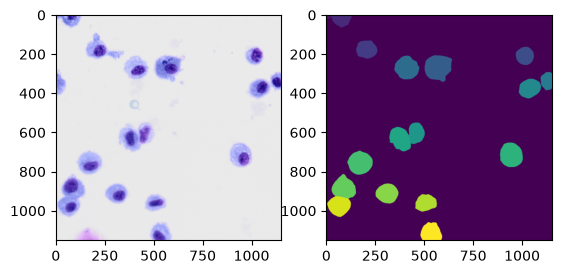

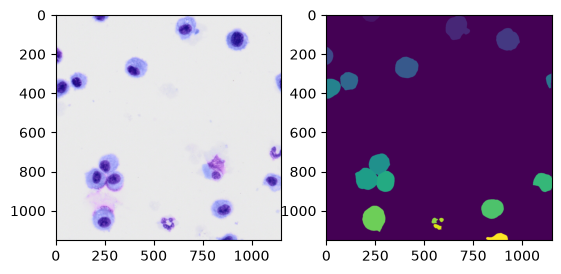

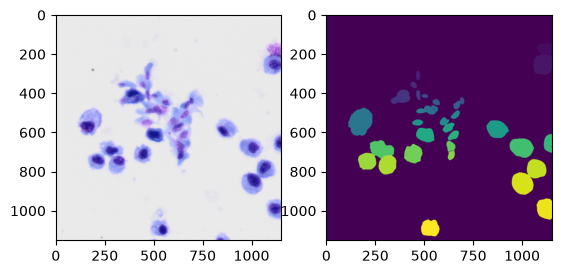

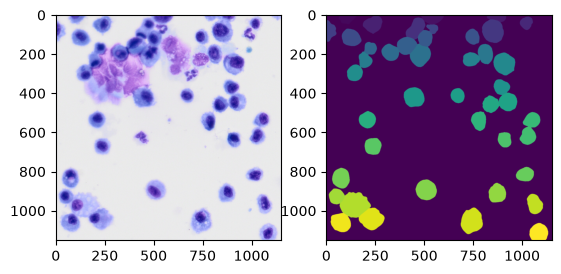

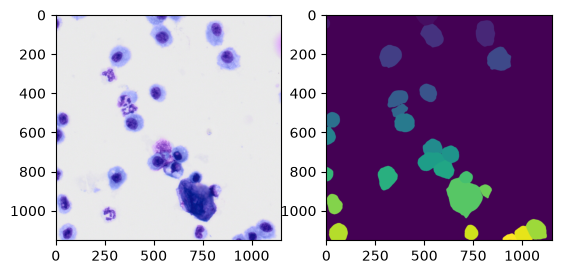

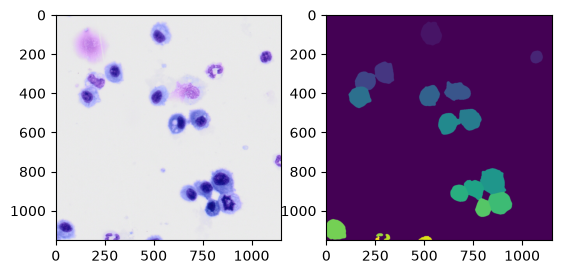

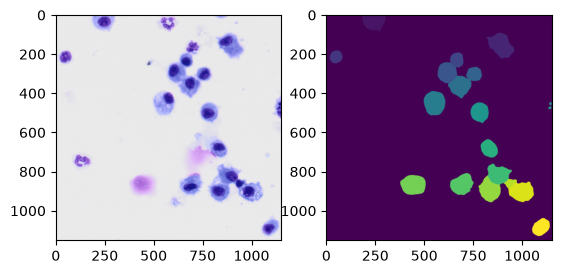

segmented 210 cells from 12 tiles in 41.1s


,global_y,global_x,area_um2,equiv_diameter_um,eccentricity,solidity,extent,mean_r,mean_g,mean_b,std_intensity,mean_hue,mean_sat,nucleus_fraction
0,2068.394660,16270.246891,102.628892,11.431149,0.366777,0.941622,0.714398,111.211778,112.150512,204.057608,0.231598,0.665215,0.511502,0.451353
1,2118.402318,16356.385072,132.771906,13.001940,0.645265,0.971970,0.730785,119.708086,111.541137,208.656630,0.191516,0.679734,0.497807,0.372774
2,2446.316849,16029.094626,175.339998,14.941547,0.469096,0.980067,0.804305,144.012952,137.881075,222.804110,0.205298,0.675693,0.414625,0.261507
3,2477.461720,15648.332417,143.413929,13.512967,0.458258,0.953575,0.674047,146.268420,136.237011,218.708023,0.231200,0.681873,0.415475,0.340531
4,2523.026752,16261.531369,138.214916,13.265772,0.669553,0.951790,0.794819,136.500000,128.011950,217.006790,0.221596,0.679277,0.447604,0.362167


In [24]:
import time

demo_tiles = [(y0, x0) for y0 in range(0, 5 * 1024, 1024) for x0 in range(12 * 1024, 18 * 1024, 1024)]
demo_tiles = [t for t in demo_tiles if not (
    (lambda tile: (tile.mean(axis=-1) > 225).mean() > 0.9)(read_tile(full_res, *t, 1024))
)]
print(f"{len(demo_tiles)} tissue tiles in demo region")

all_cells = []
t0 = time.time()
for y0, x0 in demo_tiles:
    tile, masks, kept = segment_tile(model, full_res, y0, x0)

    fig, ax = plt.subplots(1, 2)
    ax[0].imshow(tile)
    ax[1].imshow(masks)
    plt.show()
    all_cells.extend(extract_features(tile, masks, kept))
print(f"segmented {len(all_cells)} cells from {len(demo_tiles)} tiles in {time.time() - t0:.1f}s")

cells = pd.DataFrame(all_cells)
cells.head()

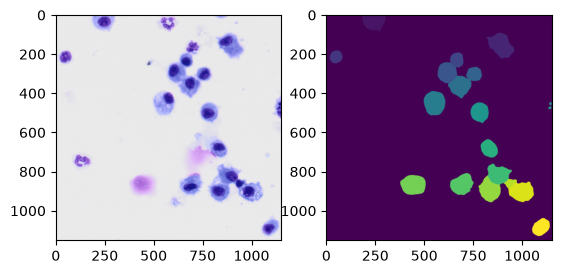

## Grouping cells into classes

No ground-truth labels exist for this slide, so this starts unsupervised: standardize the shape/color/nucleus-fraction features and k-means into `N_CLUSTERS` groups. `k=4` maps to the usual BAL differential categories (macrophage / lymphocyte / neutrophil / eosinophil); bump to 5 to split out a rarer "other/epithelial" group if the example crops below suggest one is being lumped in.

This is a starting point, not a diagnosis-grade classifier — see the note at the end on turning it into a proper supervised model once you've reviewed and corrected some labels.

In [32]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

FEATURE_COLS = [
    "area_um2", "equiv_diameter_um", "eccentricity", "solidity", "extent",
    "mean_r", "mean_g", "mean_b", "std_intensity", "mean_hue", "mean_sat",
    "nucleus_fraction",
]
N_CLUSTERS = 4

X = StandardScaler().fit_transform(cells[FEATURE_COLS])
cells["cluster"] = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=0).fit_predict(X)

cells.groupby("cluster")[FEATURE_COLS].mean().round(2)

,area_um2,equiv_diameter_um,eccentricity,solidity,extent,mean_r,mean_g,mean_b,std_intensity,mean_hue,mean_sat,nucleus_fraction
cluster,,,,,,,,,,,,
0,130.15,12.65,0.52,0.97,0.73,112.70,109.97,206.97,0.20,0.67,0.52,0.41
1,34.88,6.23,0.72,0.95,0.71,141.84,111.59,214.96,0.10,0.72,0.49,0.57
2,240.10,17.33,0.56,0.94,0.72,182.72,158.49,233.38,0.15,0.71,0.34,0.36
3,171.25,14.68,0.48,0.97,0.75,143.18,136.95,222.54,0.20,0.68,0.42,0.30


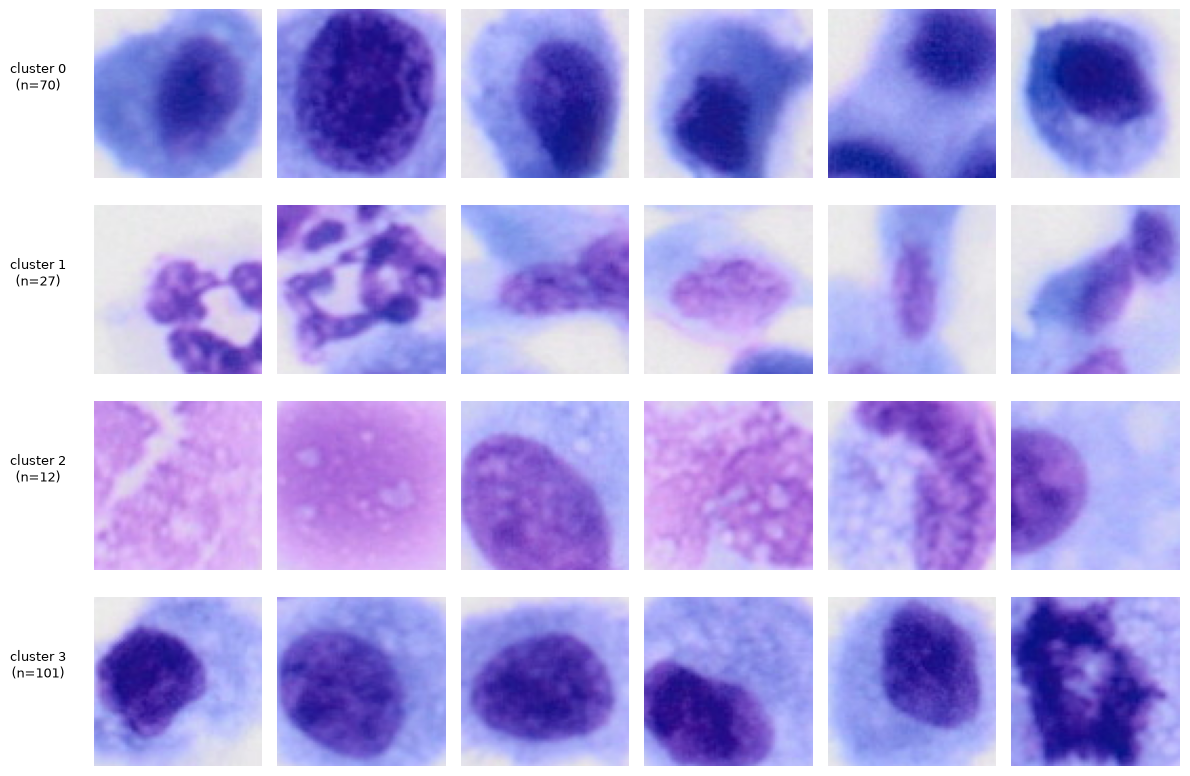

In [33]:
def show_cluster_examples(cells, z, n_per_cluster=6, crop=80):
    clusters = sorted(cells["cluster"].unique())
    fig, axes = plt.subplots(len(clusters), n_per_cluster, figsize=(2 * n_per_cluster, 2 * len(clusters)))
    for row, c in enumerate(clusters):
        sample = cells[cells["cluster"] == c].sample(min(n_per_cluster, (cells["cluster"] == c).sum()), random_state=0)
        for col, (_, cell) in enumerate(sample.iterrows()):
            y, x = int(cell.global_y), int(cell.global_x)
            patch = read_tile(z, y - crop // 2, x - crop // 2, crop)
            ax = axes[row, col] if len(clusters) > 1 else axes[col]
            ax.imshow(patch)
            ax.axis("off")
            if col == 0:
                ax.set_ylabel(f"cluster {c}\n(n={sum(cells.cluster==c)})", rotation=0, labelpad=40, fontsize=9)
                ax.axis("on"); ax.set_xticks([]); ax.set_yticks([])
                for spine in ax.spines.values():
                    spine.set_visible(False)
    plt.tight_layout()
    plt.show()


show_cluster_examples(cells, full_res)

In [35]:
cells.columns

Index(['global_y', 'global_x', 'area_um2', 'equiv_diameter_um', 'eccentricity',
       'solidity', 'extent', 'mean_r', 'mean_g', 'mean_b', 'std_intensity',
       'mean_hue', 'mean_sat', 'nucleus_fraction', 'cluster'],
      dtype='str')

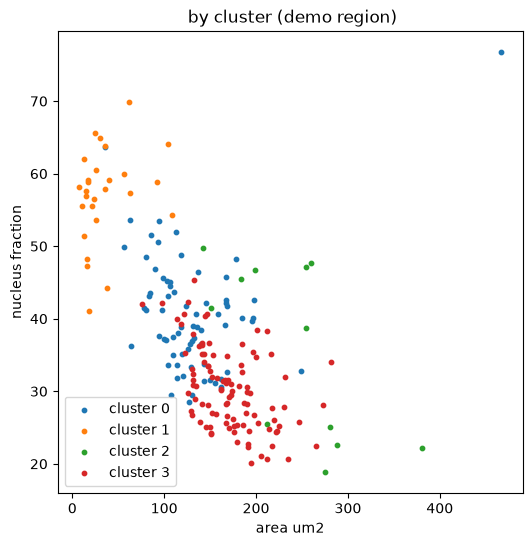

In [43]:
# Spatial sanity check: clusters should form coherent patches, not salt-and-pepper noise,
# if the features are actually capturing real cell-type differences.
plt.figure(figsize=(6, 6))
for c in sorted(cells["cluster"].unique()):
    sub = cells[cells["cluster"] == c]
    plt.scatter(sub.area_um2, 100*sub.nucleus_fraction, s=10, label=f"cluster {c}")
plt.xlabel("area um2")
plt.ylabel("nucleus fraction")

plt.legend()
plt.title(" by cluster (demo region)")
plt.show()

## Scaling to the full slide

```python
tissue_tiles = find_tissue_tiles(full_res)   # ~30s, scans the whole grid
all_cells = []
for y0, x0 in tissue_tiles:
    tile, masks, kept = segment_tile(model, full_res, y0, x0)
    all_cells.extend(extract_features(tile, masks, kept))
cells = pd.DataFrame(all_cells)
cells.to_parquet("../SFS/bal2_cells.parquet")
```

Measured on this machine: **775 of 2860 tiles contain tissue** (the smear covers about a quarter of the slide), and the demo above ran at ~3.3s/tile including feature extraction — so a full-slide run is roughly **43 minutes** on this GPU. Run it as a background script rather than in the notebook — a 43-minute loop in a live kernel is fragile (kernel restarts, laptop sleep, etc. all lose progress). Write `all_cells` to disk incrementally (e.g. append each tile's rows to a CSV, or checkpoint the DataFrame every N tiles) so an interruption doesn't cost you the whole run.

## Next steps: from clusters to a real classifier

K-means on hand-picked features is a fast way to get *a* grouping, not a validated one — the clusters above should be treated as a starting hypothesis, not ground truth. On the demo region, they already split out something real: **cluster 1's multilobed nuclei are a clean neutrophil signature** (visually unmistakable in the crops above), which is a good sign the shape/nucleus-fraction features are picking up genuine biology, not noise. Cluster 2, on the other hand, looks like it's catching a couple of non-cellular pink blobs (mucus/debris) alongside real cells — worth adding a sanity filter (e.g. drop cells with very low solidity, or very low `std_intensity`, indicating a mask with no real internal structure) before it feeds into clustering.

To turn this into something you'd trust for actual cell counts:

1. **Review and correct.** Look at `show_cluster_examples` output above. If a cluster is visually a clean, single cell type, name it. If it's a mix, that's a sign the features aren't separating it well (or `N_CLUSTERS` is too low) — expect this for eosinophils in particular, since Diff-Quik-style stains don't always show the eosin-orange granules as distinctly as an H&E stain would.
2. **Curate a labeled set.** Sample ~30-50 cells per cluster, look at them individually (`read_tile` around each `global_y`/`global_x`), and assign a corrected label. A few hundred labeled cells total is enough to start.
3. **Train a supervised classifier on the corrected labels** — either a `RandomForestClassifier` on the same `FEATURE_COLS` (fast, interpretable, good baseline), or fine-tune a small CNN on the cropped image patches directly if the feature-based approach plateaus (color/shape alone won't capture everything, e.g. nuclear texture/lobulation).
4. **Re-run the classifier** (not k-means) over every segmented cell for the final per-cell labels.

This mirrors the standard approach for this kind of task: unsupervised clustering to bootstrap fast, human review to get real labels cheaply, supervised model for the final, reproducible classification.

## Exporting crops for manual correction (Cellpose GUI)

The GUI reads ordinary image files (PNG/TIFF/JPG) — it can't open `bal2.zarr` directly. So the hand-off is: pull a diverse sample of tiles out of the zarr with `read_tile` (same helper the pipeline already uses), save them as PNGs, correct those in the GUI, then feed the corrected `_seg.npy` files straight into `cellpose.train.train_seg` for fine-tuning.

Sampling from across the whole slide (not just the demo region) matters more than sampling a lot of tiles — 20-30 tiles covering different densities/regions is a better fine-tuning set than 100 tiles from one patch.

In [ ]:
import random
from skimage.io import imsave

GUI_REVIEW_DIR = Path("../SFS/gui_review_tiles")
GUI_REVIEW_DIR.mkdir(exist_ok=True, parents=True)


def export_tiles_for_gui(z, origins, out_dir, size=1024):
    """Save raw RGB crops as PNGs so they can be opened in the Cellpose GUI.

    Filenames encode the global (y0, x0) origin so a corrected tile can be traced
    back to its location on the slide later if needed.
    """
    paths = []
    for y0, x0 in origins:
        tile = read_tile(z, y0, x0, size)
        path = out_dir / f"tile_y{y0}_x{x0}.png"
        imsave(path, tile, check_contrast=False)
        paths.append(path)
    return paths


random.seed(0)
tissue_tiles = find_tissue_tiles(full_res)  # ~30s, scans the whole grid
review_tiles = random.sample(tissue_tiles, min(25, len(tissue_tiles)))
exported = export_tiles_for_gui(full_res, review_tiles, GUI_REVIEW_DIR)
print(f"exported {len(exported)} tiles to {GUI_REVIEW_DIR}")

### Correcting masks in the GUI

1. In a terminal: `conda activate cellpose_seg && python -m cellpose`
2. **File > Load image** (or drag a PNG from `gui_review_tiles/` onto the window).
3. Pick a model in the right-hand panel — e.g. `cpsam`, the same model this pipeline already uses — and run it to get an initial prediction. You're correcting mistakes, not drawing from scratch, since the base model should already get most cells roughly right.
4. Fix what's wrong:
   - **Left-click and drag** to trace a new outline around a missed cell (releasing closes the loop into a mask).
   - **Right-click** an existing mask to delete it — use this for debris that got segmented as a cell, or before redrawing a merged/split mistake as separate cells.
   - **Ctrl+Z** undoes the last edit.
   - **O** toggles mask outlines on/off so you can see the underlying image.
5. **Ctrl+S** (or File > Save) writes `tile_y..._x..._seg.npy` next to the PNG — image + your corrected masks together. That's exactly the format `cellpose.train.train_seg` / the `--train` CLI expect, so no conversion step is needed.
6. Repeat for the rest of the exported tiles.

Once you have a folder of corrected `_seg.npy` files, fine-tune from the pretrained weights rather than from scratch:

```python
from cellpose import train

train.train_seg(
    model.net,
    train_dir=str(GUI_REVIEW_DIR),   # picks up the *_seg.npy files directly
    n_epochs=100,
    learning_rate=1e-5,
)
```

Check `help(train.train_seg)` in this cellpose version first — hold back a few corrected tiles as a `test_dir` if the signature supports it, so you can measure whether fine-tuning actually improved matches over the base model rather than assuming it did.